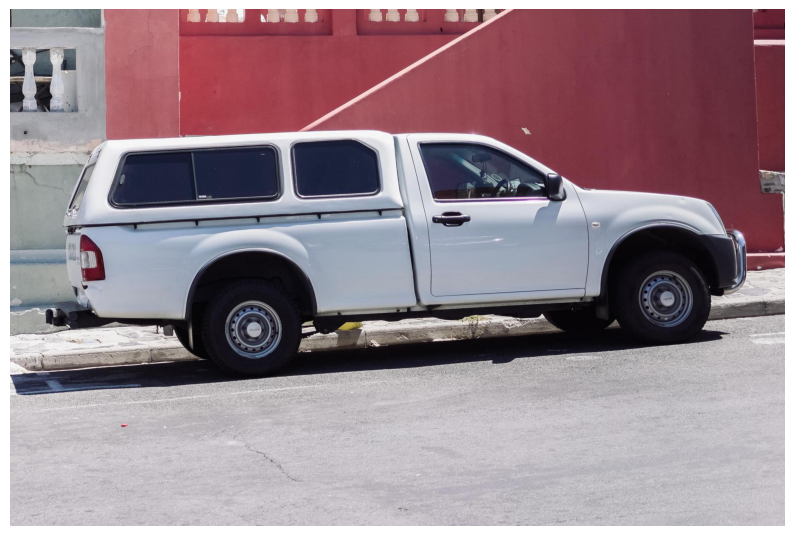

In [1]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "notebooks/images/truck.jpg"

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(10, 7))
plt.imshow(image)
plt.axis("off")
plt.show()

In [2]:
import numpy as np
import torch

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

device = "cpu"
checkpoint = "checkpoints/sam2.1_hiera_tiny.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_t.yaml"

sam2_model = build_sam2(model_cfg, checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 predictor ready on:", device)

SAM2 predictor ready on: cpu


/home/tomas/projects/machine-vision/sam2/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
image_np = np.array(image)

predictor.set_image(image_np)

print("Image processed; ready for a prompt.")

Image processed; ready for a prompt.


In [4]:
input_point = np.array([[500, 375]])
input_label = np.array([1])

masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)

best_mask_index = np.argmax(scores)
best_mask = masks[best_mask_index]

print("Mask shape:", best_mask.shape)
print("Scores:", scores)
print("Best score:", scores[best_mask_index])

Mask shape: (1200, 1800)
Scores: [0.0421533  0.9520052  0.49307582]
Best score: 0.9520052


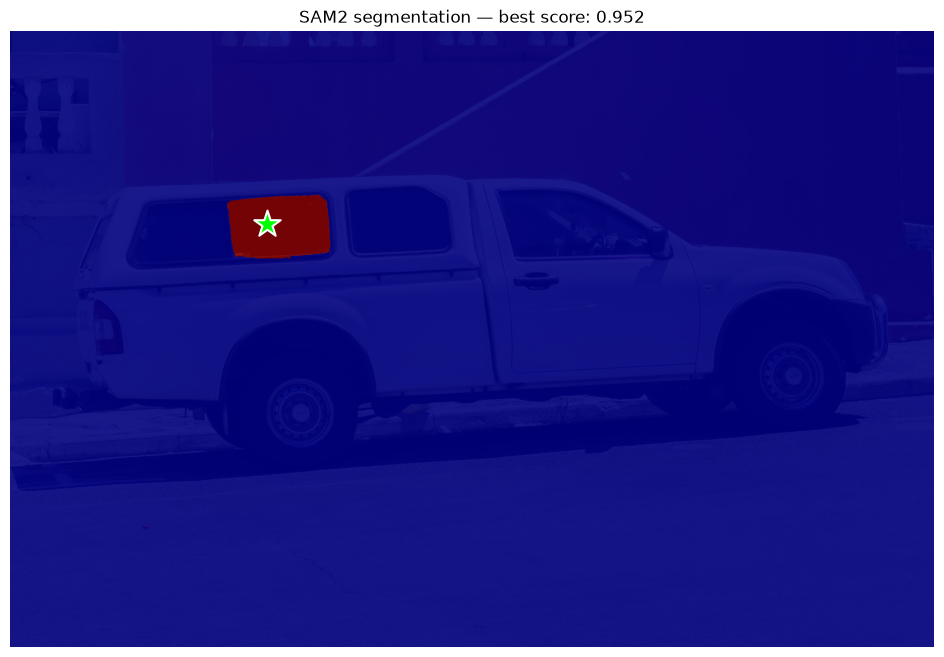

In [6]:
plt.figure(figsize=(12, 8))

plt.imshow(image)
plt.imshow(best_mask, cmap="jet", alpha=0.9)

plt.scatter(
    input_point[:, 0],
    input_point[:, 1],
    color="lime",
    marker="*",
    s=400,
    edgecolor="white",
    linewidth=1.5,
)

plt.title(f"SAM2 segmentation — best score: {scores[best_mask_index]:.3f}")
plt.axis("off")
plt.show()